# 01 · Исследование данных KION

Перед обучением посмотрел, как устроены просмотры: сколько истории есть у пользователей, насколько популярность сосредоточена на отдельных фильмах и что означает процент просмотра.

В таблице 5 476 251 взаимодействие и 962 179 пользователей. Каждая строка — агрегированная пара пользователь–объект с датой последнего просмотра. Это важно для разбиения: более ранних событий этой пары в выгрузке уже нет.

Даты в CSV относятся к марту–августу 2021 года. Для экспериментов использую их, хотя в описании источника встречается другой год.

## Загрузка данных

Входные CSV расположены в `data/`. Пути указаны относительно каталога `notebooks/`.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA_DIR = Path(os.environ.get("KION_DATA_DIR", ROOT / "data"))
REPORTS = ROOT / "reports" / "full"
K = 10
blas_limit = threadpool_limits(limits=1, user_api="blas")
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

In [2]:
from kion_recsys.data import (
    TEST_START,
    cold_start_stats,
    load_interactions,
    split_interactions,
)

In [3]:
interactions = load_interactions(DATA_DIR)
users = pd.read_csv(DATA_DIR / "users.csv")
items = pd.read_csv(DATA_DIR / "items.csv")

display(interactions.head())
display(users.head())
display(items[["item_id", "title", "content_type", "release_year", "genres"]].head())

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


,user_id,age,income,sex,kids_flg
0,973171,age_25_34,income_60_90,М,1
1,962099,age_18_24,income_20_40,М,0
2,1047345,age_45_54,income_40_60,Ж,0
3,721985,age_45_54,income_20_40,Ж,0
4,704055,age_35_44,income_60_90,Ж,0


,item_id,title,content_type,release_year,genres
0,10711,Поговори с ней,film,2002.0,"драмы, зарубежные, детективы, мелодрамы"
1,2508,Голые перцы,film,2014.0,"зарубежные, приключения, комедии"
2,10716,Тактическая сила,film,2011.0,"криминал, зарубежные, триллеры, боевики, комедии"
3,7868,45 лет,film,2015.0,"драмы, зарубежные, мелодрамы"
4,16268,Все решает мгновение,film,1978.0,"драмы, спорт, советские, мелодрамы"


## Структура и качество данных

Размеры таблиц, пропуски, повторяющиеся идентификаторы и аномальные значения.

In [4]:
tables = {"interactions": interactions, "users": users, "items": items}

for name, table in tables.items():
    print(f"{name}: {len(table):,} rows, {table.shape[1]} columns")

print("Unique users:", interactions["user_id"].nunique())
print("Unique items:", interactions["item_id"].nunique())
print(
    "Date range:",
    interactions["last_watch_dt"].min().date(),
    "—",
    interactions["last_watch_dt"].max().date(),
)

interactions: 5,476,251 rows, 5 columns
users: 840,197 rows, 5 columns
items: 15,963 rows, 14 columns
Unique users: 962179
Unique items: 15706
Date range: 2021-03-13 — 2021-08-22


In [5]:
for name, table in tables.items():
    missing_pct = table.isna().mean().mul(100)
    print(f"\n{name}")
    display(
        missing_pct[missing_pct > 0]
        .sort_values(ascending=False)
        .round(2)
        .to_frame("missing_pct")
    )


interactions


,missing_pct
watched_pct,0.02



users


,missing_pct
income,1.76
age,1.68
sex,1.65



items


,missing_pct
for_kids,96.45
studios,93.33
title_orig,29.72
actors,16.41
directors,9.45
keywords,2.65
release_year,0.61
countries,0.23
age_rating,0.01
description,0.01


In [6]:
print(
    "Duplicate user-item pairs:", interactions.duplicated(["user_id", "item_id"]).sum()
)
print("Duplicate user IDs:", users["user_id"].duplicated().sum())
print("Duplicate item IDs:", items["item_id"].duplicated().sum())
print(
    "Invalid watch percentages:",
    ((interactions["watched_pct"] < 0) | (interactions["watched_pct"] > 100)).sum(),
)

Duplicate user-item pairs: 0
Duplicate user IDs: 0
Duplicate item IDs: 0
Invalid watch percentages: 0


### Покрытие метаданными

Проверю, для какой части просмотров есть описания пользователей и контента. Для коллаборативных моделей достаточно самих взаимодействий, поэтому отсутствие строки в users.csv не мешает включить просмотр в историю.

In [7]:
user_coverage = interactions["user_id"].drop_duplicates().isin(users["user_id"]).mean()
item_coverage = interactions["item_id"].drop_duplicates().isin(items["item_id"]).mean()

print(f"Users with metadata: {user_coverage:.1%}")
print(f"Items with metadata: {item_coverage:.1%}")

Users with metadata: 77.4%
Items with metadata: 100.0%


## Активность пользователей и популярность контента

Основные характеристики для выбора моделей — **разреженность** матрицы взаимодействий и **длинный хвост** популярности. Небольшое число просмотров у большинства пользователей усложняет персонализацию, а концентрация популярности снижает охват каталога.

In [8]:
user_activity = interactions.groupby("user_id").size()
item_popularity = interactions.groupby("item_id").size()

activity_stats = pd.DataFrame(
    {
        "interactions_per_user": user_activity.describe(percentiles=[0.5, 0.9, 0.99]),
        "viewers_per_item": item_popularity.describe(percentiles=[0.5, 0.9, 0.99]),
    }
)

display(activity_stats)

n_users = interactions["user_id"].nunique()
n_items = interactions["item_id"].nunique()
sparsity = 1 - len(interactions) / (n_users * n_items)
print(f"Interaction matrix sparsity: {sparsity:.4%}")

,interactions_per_user,viewers_per_item
count,962179.000000,15706.000000
mean,5.691510,348.672546
std,10.886262,3194.053580
min,1.000000,1.000000
50%,2.000000,12.000000
90%,13.000000,606.000000
99%,49.000000,4687.700000
max,1341.000000,202457.000000


Interaction matrix sparsity: 99.9638%


Матрица «пользователь × объект» разрежена. Для коллаборативных методов подходит формат `scipy.sparse` вместо плотного массива.

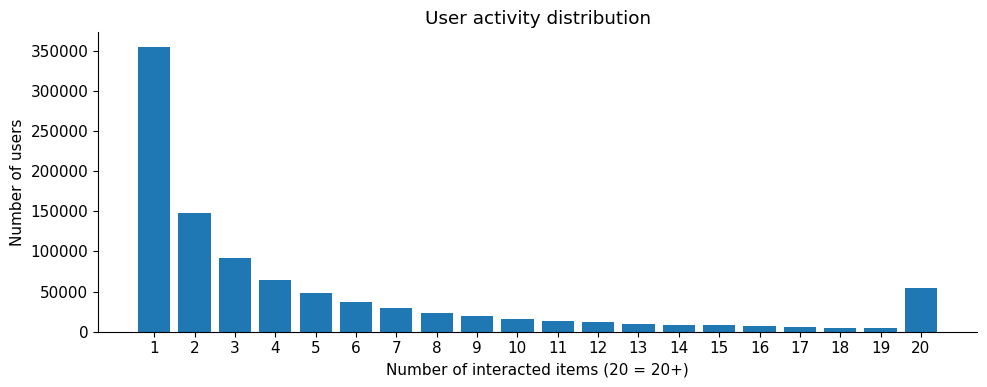

In [9]:
activity_counts = user_activity.clip(upper=20).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(activity_counts.index, activity_counts.values)
ax.set_title("User activity distribution")
ax.set_xlabel("Number of interacted items (20 = 20+)")
ax.set_ylabel("Number of users")
ax.set_xticks(activity_counts.index)
plt.tight_layout()
plt.show()

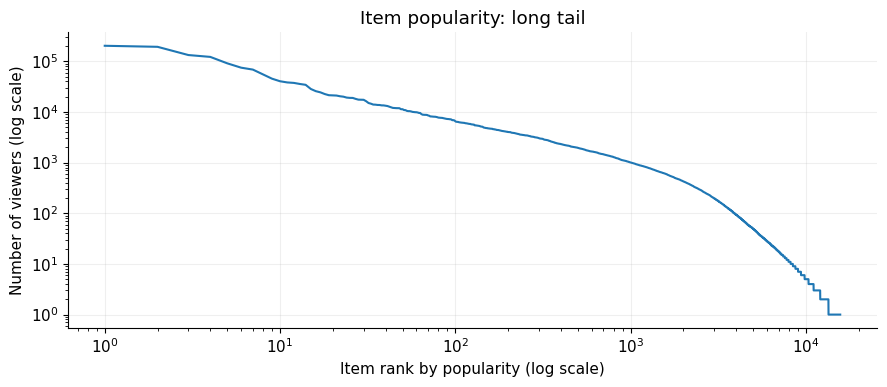

,item_id,viewers,title,content_type
0,10440,202457,Хрустальный,series
1,15297,193123,Клиника счастья,series
2,9728,132865,Гнев человеческий,film
3,13865,122119,Девятаев,film
4,4151,91167,Секреты семейной жизни,series
5,3734,74803,Прабабушка легкого поведения,film
6,2657,68581,Подслушано,series
7,4880,55043,Афера,series
8,142,45367,Маша,film
9,6809,40372,Дуров,film


In [10]:
ranked_popularity = item_popularity.sort_values(ascending=False).to_numpy()
ranks = np.arange(1, len(ranked_popularity) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(ranks, ranked_popularity)
ax.set_title("Item popularity: long tail")
ax.set_xlabel("Item rank by popularity (log scale)")
ax.set_ylabel("Number of viewers (log scale)")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

top_items = (
    item_popularity.nlargest(10)
    .rename("viewers")
    .rename_axis("item_id")
    .reset_index()
    .merge(
        items[["item_id", "title", "content_type"]],
        on="item_id",
        how="left",
        validate="one_to_one",
    )
)
display(top_items)

## Интерпретация `watched_pct`

Вместо оценок здесь длительность и процент просмотра. Чтобы построить бинарную матрицу, нужно выбрать, какой просмотр включать в историю интересов пользователя.

При сравнении фильмов и сериалов учитываются различия в длительности и способах агрегирования просмотров.

,total_dur,watched_pct
count,5.476251e+06,5.475423e+06
mean,8.295490e+03,4.637397e+01
std,4.856799e+04,4.191853e+01
min,1.000000e+00,0.000000e+00
50%,2.898000e+03,3.200000e+01
90%,1.511200e+04,1.000000e+02
95%,3.144500e+04,1.000000e+02
99%,9.008300e+04,1.000000e+02
max,8.041167e+07,1.000000e+02


Missing watch percentages: 828
Zero watch percentages: 727751
100% watch percentages: 1407197
Durations above 24 hours: 59502


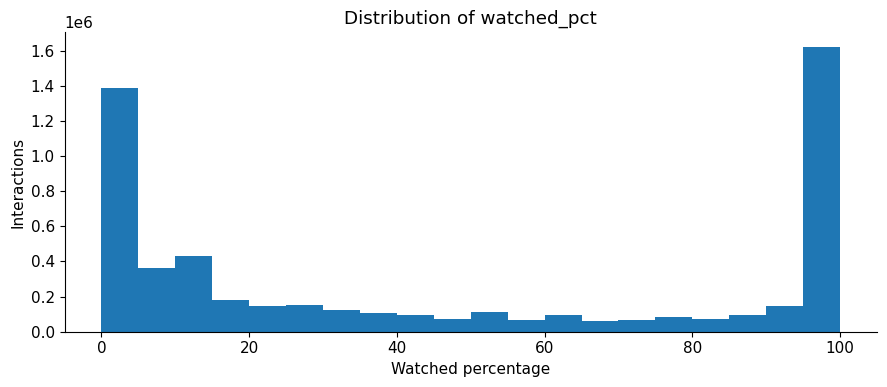

In [11]:
display(
    interactions[["total_dur", "watched_pct"]].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

print("Missing watch percentages:", interactions["watched_pct"].isna().sum())
print("Zero watch percentages:", interactions["watched_pct"].eq(0).sum())
print("100% watch percentages:", interactions["watched_pct"].eq(100).sum())
print("Durations above 24 hours:", interactions["total_dur"].gt(24 * 3600).sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(interactions["watched_pct"].dropna(), bins=np.arange(0, 105, 5))
ax.set_title("Distribution of watched_pct")
ax.set_xlabel("Watched percentage")
ax.set_ylabel("Interactions")
plt.tight_layout()
plt.show()

In [12]:
interactions_by_type = interactions[["item_id", "watched_pct"]].merge(
    items[["item_id", "content_type"]], on="item_id", how="left", validate="many_to_one"
)

watch_by_type = interactions_by_type.groupby("content_type", observed=True).agg(
    interactions=("item_id", "size"),
    median_watched_pct=("watched_pct", "median"),
    share_at_least_20_pct=("watched_pct", lambda values: values.ge(20).mean() * 100),
)

display(watch_by_type)

,interactions,median_watched_pct,share_at_least_20_pct
content_type,,,
film,4137134,45.0,60.876998
series,1339117,13.0,44.300834


### Порог положительного просмотра

Посмотрю, сколько строк остаётся при разных порогах watched_pct. Для сравнения моделей фиксирую 20%, как в исходном эксперименте; эта таблица показывает, насколько сокращается история после фильтрации.

In [13]:
threshold_stats = []

for threshold in [5, 20, 50]:
    positive = interactions.loc[interactions["watched_pct"] >= threshold]
    threshold_stats.append(
        {
            "min_watched_pct": threshold,
            "interactions": len(positive),
            "share_of_all_pct": len(positive) / len(interactions) * 100,
            "users": positive["user_id"].nunique(),
            "items": positive["item_id"].nunique(),
        }
    )

display(pd.DataFrame(threshold_stats))

,min_watched_pct,interactions,share_of_all_pct,users,items
0,5,4085835,74.610075,794008,14143
1,20,3111803,56.823601,684522,13396
2,50,2416400,44.125078,580075,12664


## Временная структура и cold start

Для сравнения моделей беру последние две недели:

- Train: до **9 августа 2021**;
- Validation: **9–15 августа 2021**;
- Test: **16–22 августа 2021**.

В этом разделе анализируются все взаимодействия без порога по `watched_pct`. В модельных экспериментах используется порог 20% как фиксированная стартовая гипотеза.

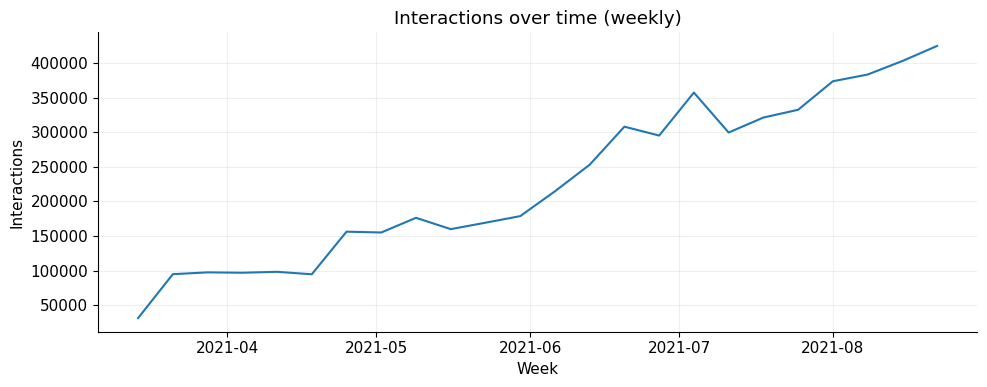

In [14]:
daily_interactions = interactions.groupby("last_watch_dt").size()
weekly_interactions = daily_interactions.resample("W-SUN").sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly_interactions.index, weekly_interactions.values)
ax.set_title("Interactions over time (weekly)")
ax.set_xlabel("Week")
ax.set_ylabel("Interactions")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [15]:
train, validation, test = split_interactions(interactions, min_watched_pct=None)

split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "interactions": len(frame),
            "users": frame["user_id"].nunique(),
            "items": frame["item_id"].nunique(),
        }
        for name, frame in [
            ("train", train),
            ("validation", validation),
            ("test", test),
        ]
    ]
)
display(split_summary)

,split,interactions,users,items
0,train,4649162,850489,15415
1,validation,402653,160794,7188
2,test,424436,167348,7106


### Новые пользователи и объекты

**User cold start:** отсутствие истории пользователя до периода рекомендаций. **Item cold start:** отсутствие взаимодействий с объектом в обучающих данных.

Доля взаимодействий новых пользователей и доля самих новых пользователей — разные показатели.

In [16]:
cold_start = pd.DataFrame(
    {
        "validation": cold_start_stats(train, validation),
        "test": cold_start_stats(
            interactions.loc[interactions["last_watch_dt"] < TEST_START], test
        ),
    }
)

display(cold_start)

,validation,test
future_users,160794.000000,167348.000000
new_users,55582.000000,56108.000000
events_from_new_users_pct,28.392934,27.727148
new_items,162.000000,129.000000
events_for_new_items_pct,3.920001,2.854141


## Что это означает для моделей

У пользователя в медиане всего 2 объекта в истории. Матрица заполнена примерно на 0,036%, поэтому плотное представление здесь не нужно. Для ItemKNN и факторизации буду использовать разреженные матрицы.

Популярность распределена неравномерно: у объекта в медиане 12 зрителей, а у самого популярного — больше 200 тысяч. Начну с рекомендаций по популярности и посмотрю, удастся ли персонализации их улучшить. Кроме точности буду считать покрытие каталога.

Порог 20% оставляет 3,11 млн взаимодействий, или 56,8% исходных строк. При этом медианный процент просмотра у фильмов — 45%, у сериалов — 13%. Единого идеального порога здесь нет; для сравнения моделей фиксирую 20%, как в исходной версии проекта. Пропусков в watched_pct немного — 828, такие строки в положительную историю не включаю.

В Validation появляются 55 582 пользователя, которых не было в предыдущей истории. Значит, резервная выдача по популярности нужна уже в первом эксперименте. Метаданные контента покрывают все объекты с просмотрами, поэтому позже попробую использовать жанры, страны и режиссёров.

Дальше — Popularity, ItemKNN и ALS.